Dados agrupados de 33371 registros horários para 1398 dias.


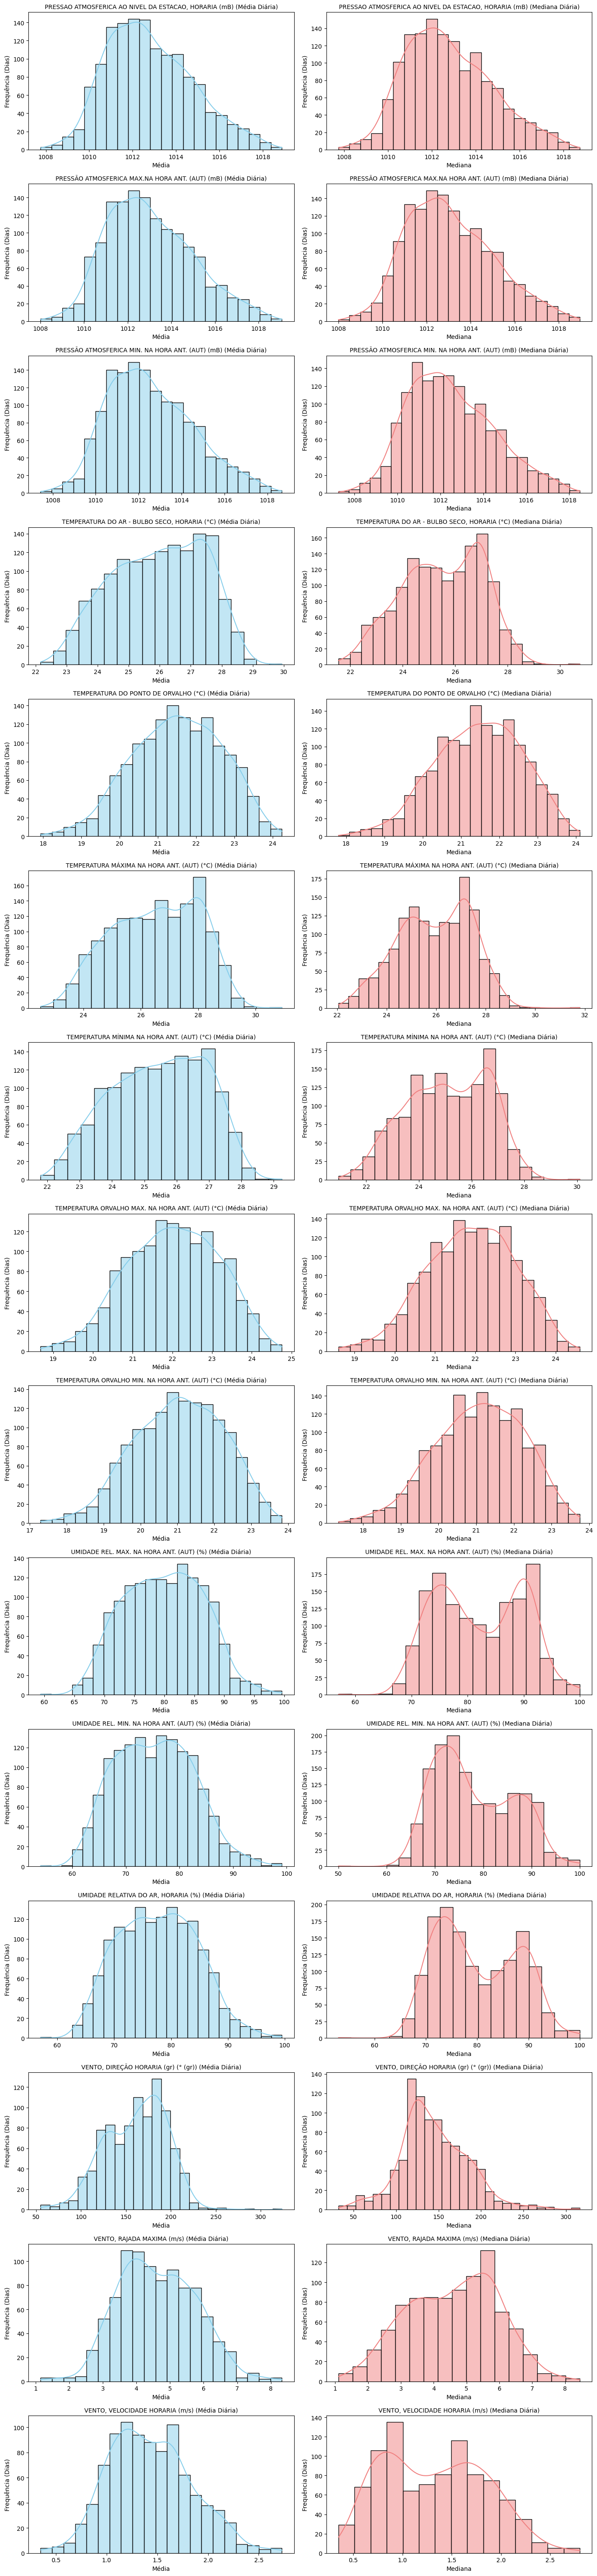

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar o dataset
df = pd.read_csv('/content/data/df_recife_datetime.csv')

# Converter datetime para o tipo correto e extrair apenas a data (dia)
df['datetime'] = pd.to_datetime(df['datetime'])
df['data_dia'] = df['datetime'].dt.date

# Definir colunas de exclusão (metadados e precipitação)
colunas_excluir = ['datetime', 'ESTACAO', 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'data_dia']

# Selecionar as variáveis meteorológicas
colunas_meteorologicas = [col for col in df.columns if col not in colunas_excluir]

# Garantir que todas as colunas selecionadas sejam tratadas como numéricas
for col in colunas_meteorologicas:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Agrupar os dados por dia, calculando a média e a mediana diária de cada variável
df_media_diaria = df.groupby('data_dia')[colunas_meteorologicas].mean().reset_index()
df_mediana_diaria = df.groupby('data_dia')[colunas_meteorologicas].median().reset_index()

print(f"Dados agrupados de {len(df)} registros horários para {len(df_media_diaria)} dias.")

# Configurar a área de plotagem em subplots
num_cols = len(colunas_meteorologicas)
if num_cols > 0:
    # Criamos um grid onde cada variável terá 2 subplots lado a lado: Média e Mediana
    fig, axes = plt.subplots(nrows=num_cols, ncols=2, figsize=(14, 4 * num_cols))

    # Caso exista apenas 1 coluna meteorológica, garante que axes seja bidimensional
    if num_cols == 1:
        axes = [axes]

    for idx, col in enumerate(colunas_meteorologicas):
        # Histograma da Média Diária (Coluna da Esquerda)
        sns.histplot(df_media_diaria[col].dropna(), ax=axes[idx][0], kde=True, color='skyblue')
        axes[idx][0].set_title(f'{col} (Média Diária)', fontsize=10)
        axes[idx][0].set_xlabel('Média')
        axes[idx][0].set_ylabel('Frequência (Dias)')

        # Histograma da Mediana Diária (Coluna da Direita)
        sns.histplot(df_mediana_diaria[col].dropna(), ax=axes[idx][1], kde=True, color='lightcoral')
        axes[idx][1].set_title(f'{col} (Mediana Diária)', fontsize=10)
        axes[idx][1].set_xlabel('Mediana')
        axes[idx][1].set_ylabel('Frequência (Dias)')

    plt.tight_layout()
    plt.show()
else:
    print("Nenhuma coluna meteorológica encontrada.")

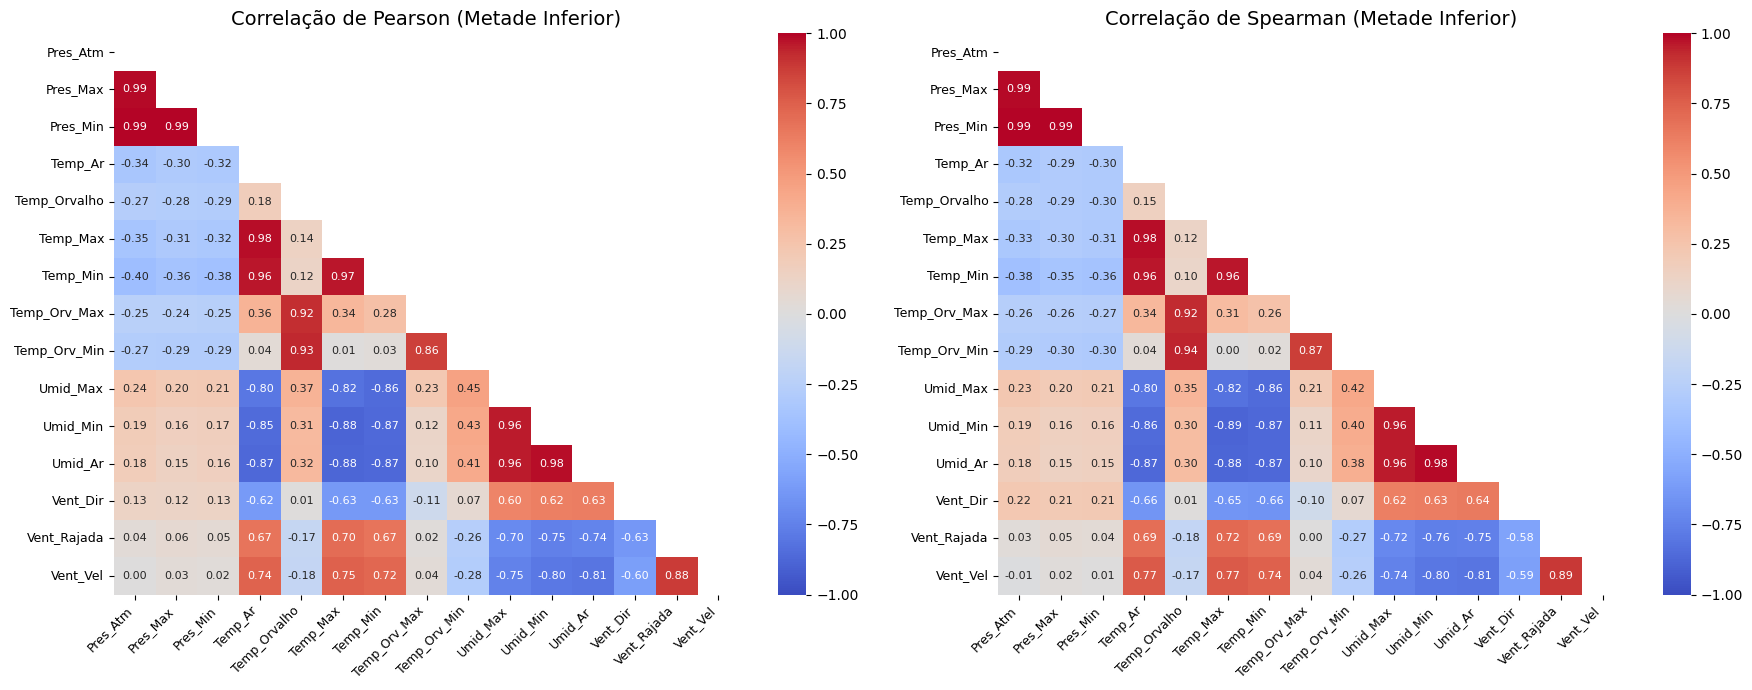

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Assegurar que as colunas meteorológicas já identificadas estão em formato numérico
for col in colunas_meteorologicas:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Filtrar apenas as variáveis de interesse
df_meteo = df[colunas_meteorologicas].copy()

# Dicionário de mapeamento para encurtar os nomes extensos das variáveis
mapeamento_nomes = {
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)': 'Pres_Atm',
    'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)': 'Pres_Max',
    'PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)': 'Pres_Min',
    'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)': 'Temp_Ar',
    'TEMPERATURA DO PONTO DE ORVALHO (°C)': 'Temp_Orvalho',
    'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)': 'Temp_Max',
    'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)': 'Temp_Min',
    'TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)': 'Temp_Orv_Max',
    'TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)': 'Temp_Orv_Min',
    'UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)': 'Umid_Max',
    'UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)': 'Umid_Min',
    'UMIDADE RELATIVA DO AR, HORARIA (%)': 'Umid_Ar',
    'VENTO, DIREÇÃO HORARIA (gr) (° (gr))': 'Vent_Dir',
    'VENTO, RAJADA MAXIMA (m/s)': 'Vent_Rajada',
    'VENTO, VELOCIDADE HORARIA (m/s)': 'Vent_Vel'
}

# Renomear as colunas para o plot
df_meteo = df_meteo.rename(columns=mapeamento_nomes)

# Calcular as matrizes de correlação
corr_pearson = df_meteo.corr(method='pearson')
corr_spearman = df_meteo.corr(method='spearman')

# Criar uma máscara para esconder o triângulo superior (já que a matriz é simétrica)
mascara = np.triu(np.ones_like(corr_pearson, dtype=bool))

# Plotar os mapas de calor para ambas as correlações
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 7))

# Pearson com máscara
sns.heatmap(corr_pearson, mask=mascara, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0], cbar=True, annot_kws={"size": 8})
axes[0].set_title('Correlação de Pearson (Metade Inferior)', fontsize=14)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right', fontsize=9)
axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0, fontsize=9)

# Spearman com máscara
sns.heatmap(corr_spearman, mask=mascara, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], cbar=True, annot_kws={"size": 8})
axes[1].set_title('Correlação de Spearman (Metade Inferior)', fontsize=14)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right', fontsize=9)
axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

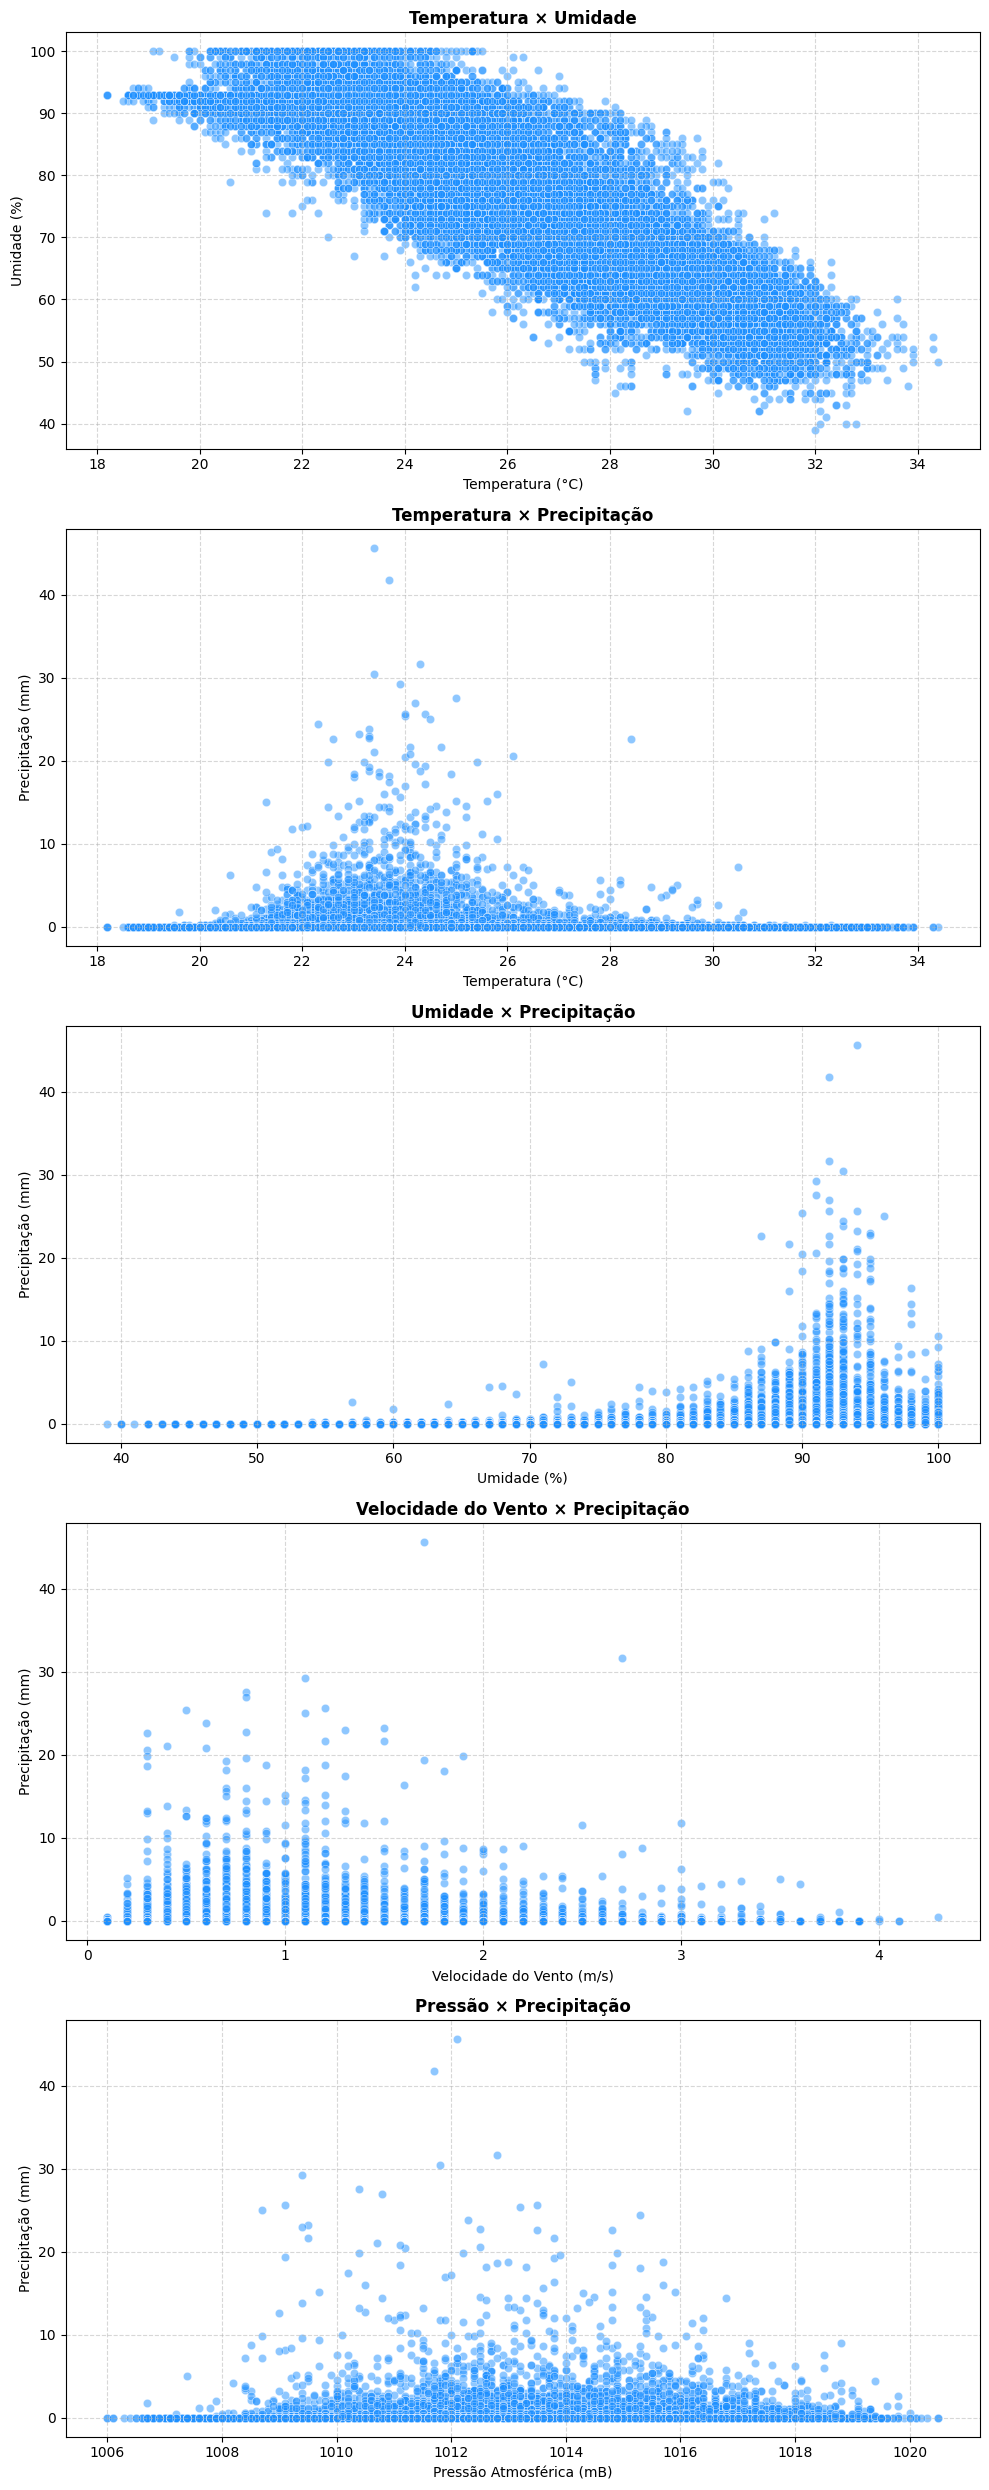

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Garantir que a precipitação seja numérica
df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'] = pd.to_numeric(df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'], errors='coerce')

# Definir as variáveis de interesse usando os nomes existentes no DataFrame
var_temp = 'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)'
var_umid = 'UMIDADE RELATIVA DO AR, HORARIA (%)'
var_precip = 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'
var_vento = 'VENTO, VELOCIDADE HORARIA (m/s)'
var_pressao = 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)'

# Lista com as definições dos plots (X, Y, Título, Labels)
plots_info = [
    (var_temp, var_umid, 'Temperatura × Umidade', 'Temperatura (°C)', 'Umidade (%)'),
    (var_temp, var_precip, 'Temperatura × Precipitação', 'Temperatura (°C)', 'Precipitação (mm)'),
    (var_umid, var_precip, 'Umidade × Precipitação', 'Umidade (%)', 'Precipitação (mm)'),
    (var_vento, var_precip, 'Velocidade do Vento × Precipitação', 'Velocidade do Vento (m/s)', 'Precipitação (mm)'),
    (var_pressao, var_precip, 'Pressão × Precipitação', 'Pressão Atmosférica (mB)', 'Precipitação (mm)')
]

# Configurar a figura com 5 subplots dispostos verticalmente
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(10, 25))

# Amostrar os dados caso o dataset seja muito grande para plotar de forma fluida (opcional, aqui plotamos tudo)
for i, (col_x, col_y, titulo, label_x, label_y) in enumerate(plots_info):
    sns.scatterplot(data=df, x=col_x, y=col_y, ax=axes[i], alpha=0.5, color='dodgerblue')
    axes[i].set_title(titulo, fontsize=12, fontweight='bold')
    axes[i].set_xlabel(label_x)
    axes[i].set_ylabel(label_y)
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

--- Estatísticas Comparativas (Sem Chuva vs Com Chuva) ---


classe_chuva                                                 Com chuva  \
TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)       mean      24.085418   
                                                   median    23.800000   
                                                   std        1.804907   
UMIDADE RELATIVA DO AR, HORARIA (%)                mean      89.431377   
                                                   median    91.000000   
                                                   std        6.704562   
VENTO, VELOCIDADE HORARIA (m/s)                    mean       1.077416   
                                                   median     0.900000   
                                                   std        0.695595   
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARI... mean    1013.564450   
                                                   median  1013.500000   
                                                   std        2.208217   

classe_chuva                                                 Sem chuva  
TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)       mean      26.246738  
                                                   median    26.200000  
                                                   std        2.819942  
UMIDADE RELATIVA DO AR, HORARIA (%)                mean      75.835283  
                                                   median    75.000000  
                                                   std       12.526666  
VENTO, VELOCIDADE HORARIA (m/s)                    mean       1.509038  
                                                   median     1.500000  
                                                   std        0.877168  
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARI... mean    1012.709574  
                                                   median  1012.500000  
                                                   std        2.172826

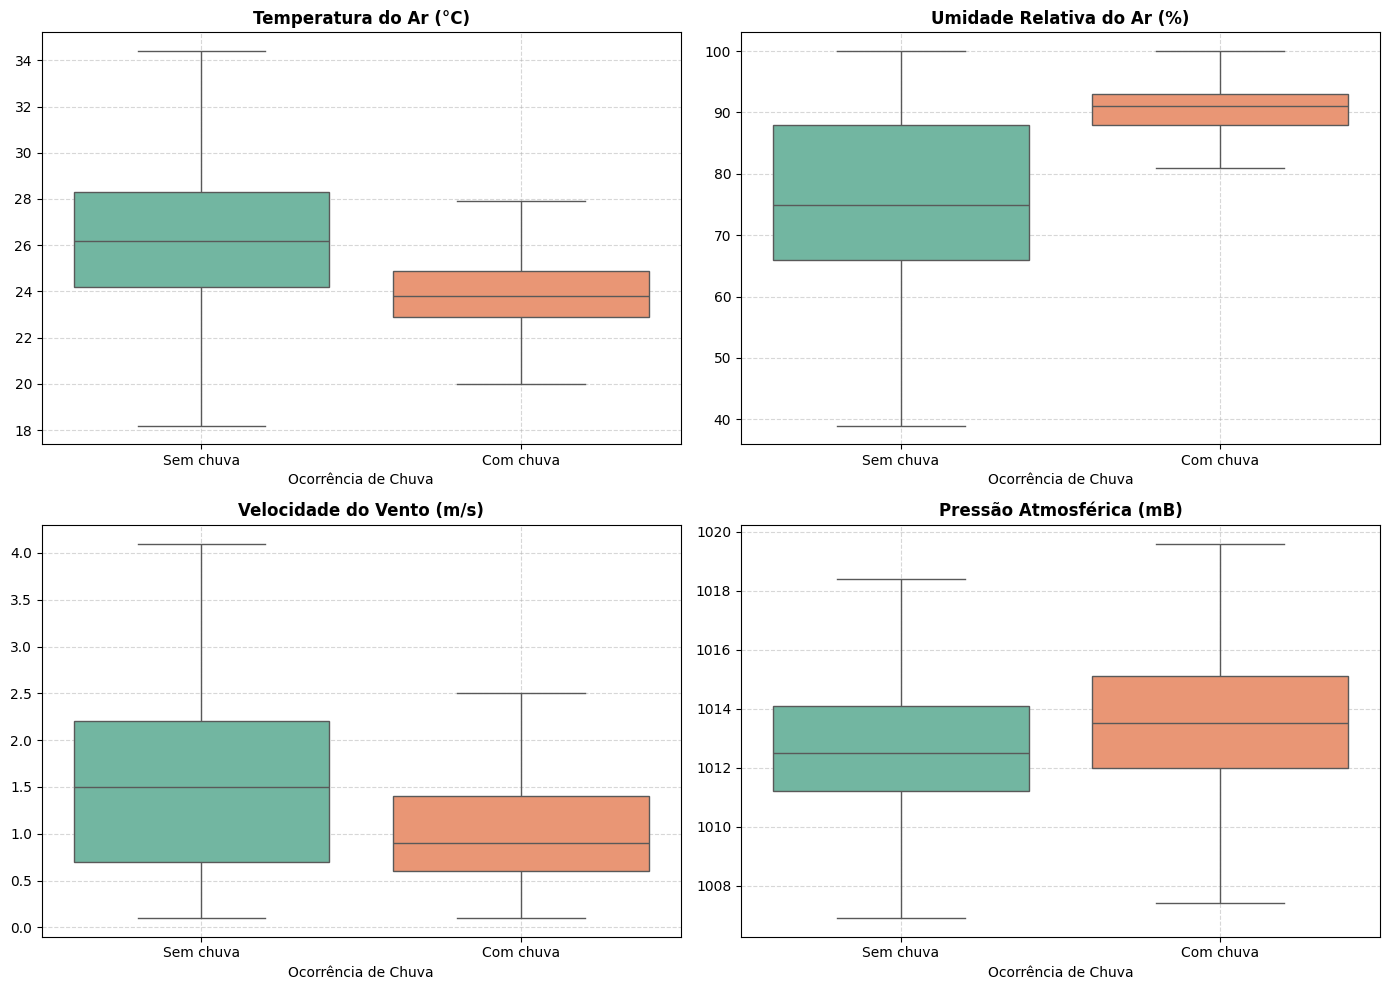

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Garantir que a coluna de precipitação seja numérica e remover nulos para a classificação
df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'] = pd.to_numeric(df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'], errors='coerce')

# Criar a coluna estratificada (Sem chuva vs Com chuva)
# Consideramos chuva qualquer valor de precipitação maior que 0 mm
df['classe_chuva'] = df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'].apply(
    lambda x: 'Com chuva' if x > 0 else ('Sem chuva' if x == 0 else None)
)

# Filtrar apenas as linhas com classificação válida de chuva
df_filtrado = df.dropna(subset=['classe_chuva']).copy()

# Definir as principais variáveis para análise (usando nomes encurtados ou originais do kernel)
# Para visualização e tabelas limpas, vamos focar em algumas variáveis chave
variaveis_analise = [
    'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)',
    'VENTO, VELOCIDADE HORARIA (m/s)',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)'
]

# Garantir que as variáveis de análise sejam numéricas
for var in variaveis_analise:
    df_filtrado[var] = pd.to_numeric(df_filtrado[var], errors='coerce')

# 2. Comparar as estatísticas (Média, Mediana e Desvio Padrão)
estatisticas_estratificadas = df_filtrado.groupby('classe_chuva')[variaveis_analise].agg(['mean', 'median', 'std']).T
print("--- Estatísticas Comparativas (Sem Chuva vs Com Chuva) ---")
display(estatisticas_estratificadas)

# 3. Visualizar as diferenças com boxplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()

# Mapeamento para títulos de exibição mais amigáveis nos plots
titulos_amigaveis = {
    'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)': 'Temperatura do Ar (°C)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)': 'Umidade Relativa do Ar (%)',
    'VENTO, VELOCIDADE HORARIA (m/s)': 'Velocidade do Vento (m/s)',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)': 'Pressão Atmosférica (mB)'
}

for i, var in enumerate(variaveis_analise):
    sns.boxplot(
        data=df_filtrado,
        x='classe_chuva',
        y=var,
        ax=axes[i],
        hue='classe_chuva',
        palette='Set2',
        legend=False,
        showfliers=False  # Remove outliers extremos para melhor visualização da distribuição principal
    )
    axes[i].set_title(titulos_amigaveis[var], fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Ocorrência de Chuva')
    axes[i].set_ylabel('')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

--- Estatísticas por Faixa de Intensidade de Precipitação ---


faixa_precipitacao                                            Sem chuva  \
TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)       mean       26.246738   
                                                   median     26.200000   
                                                   count   28786.000000   
UMIDADE RELATIVA DO AR, HORARIA (%)                mean       75.835283   
                                                   median     75.000000   
                                                   count   28722.000000   
VENTO, VELOCIDADE HORARIA (m/s)                    mean        1.509038   
                                                   median      1.500000   
                                                   count   18478.000000   
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARI... mean     1012.709574   
                                                   median   1012.500000   
                                                   count   28786.000000   

faixa_precipitacao                                          Chuva leve  \
TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)       mean      24.165937   
                                                   median    23.900000   
                                                   count   3561.000000   
UMIDADE RELATIVA DO AR, HORARIA (%)                mean      88.831728   
                                                   median    91.000000   
                                                   count   3530.000000   
VENTO, VELOCIDADE HORARIA (m/s)                    mean       1.092415   
                                                   median     0.900000   
                                                   count   2571.000000   
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARI... mean    1013.599073   
                                                   median  1013.600000   
                                                   count   3561.000000   

faixa_precipitacao                                         Chuva moderada  \
TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)       mean         23.778205   
                                                   median       23.700000   
                                                   count       858.000000   
UMIDADE RELATIVA DO AR, HORARIA (%)                mean         91.489336   
                                                   median       92.000000   
                                                   count       844.000000   
VENTO, VELOCIDADE HORARIA (m/s)                    mean          1.029108   
                                                   median        0.900000   
                                                   count       639.000000   
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARI... mean       1013.514103   
                                                   median     1013.450000   
                                                   count       858.000000   

faixa_precipitacao                                         Chuva elevada  
TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)       mean        23.869159  
                                                   median      23.800000  
                                                   count      107.000000  
UMIDADE RELATIVA DO AR, HORARIA (%)                mean        92.981308  
                                                   median      93.000000  
                                                   count      107.000000  
VENTO, VELOCIDADE HORARIA (m/s)                    mean         0.981250  
                                                   median       0.850000  
                                                   count       80.000000  
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARI... mean      1012.815888  
                                                   median    1013.000000  
                                                   count      107.000000

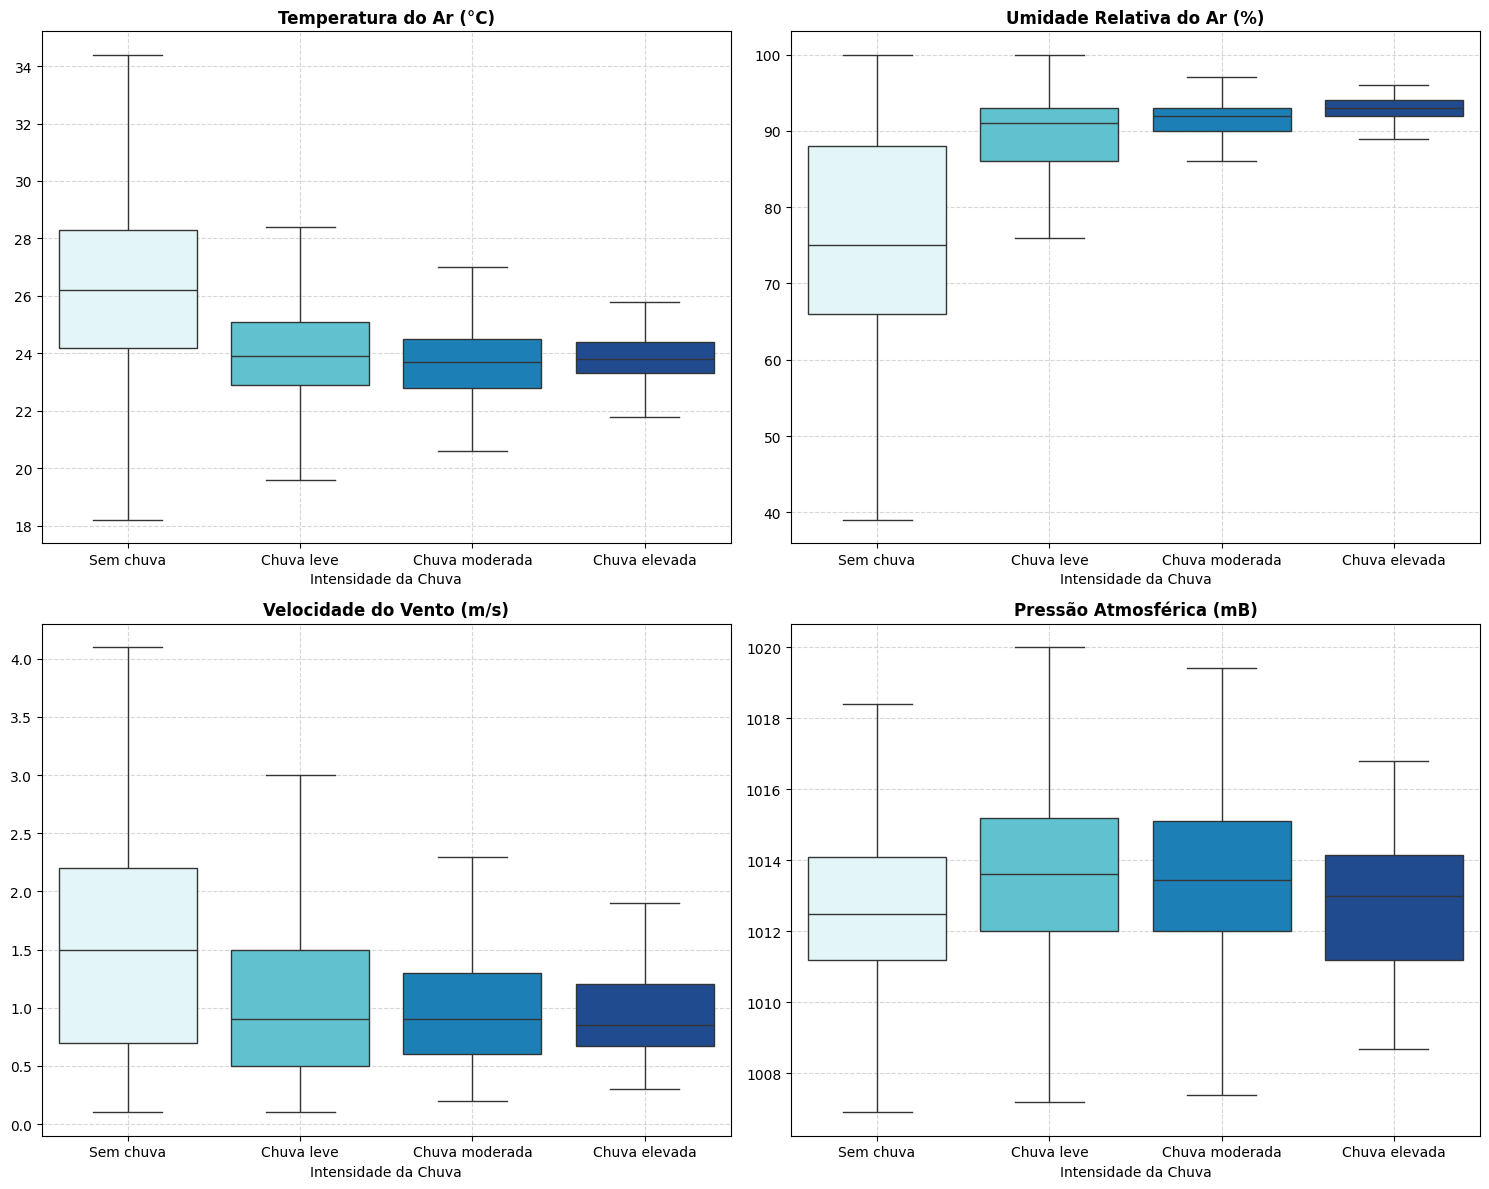

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Garantir que a coluna de precipitação seja numérica
df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'] = pd.to_numeric(df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'], errors='coerce')

# Definir função para categorizar a intensidade da chuva
def categorizar_precipitacao(x):
    if pd.isna(x):
        return None
    elif x == 0:
        return 'Sem chuva'
    elif 0 < x <= 2:
        return 'Chuva leve'
    elif 2 < x <= 10:
        return 'Chuva moderada'
    else:
        return 'Chuva elevada'

# Criar a nova coluna de estratificação por faixas
df['faixa_precipitacao'] = df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'].apply(categorizar_precipitacao)

# Filtrar nulos da categorização
df_faixas = df.dropna(subset=['faixa_precipitacao']).copy()

# Definir ordem das faixas para fins de visualização e tabelas
ordem_faixas = ['Sem chuva', 'Chuva leve', 'Chuva moderada', 'Chuva elevada']
df_faixas['faixa_precipitacao'] = pd.Categorical(df_faixas['faixa_precipitacao'], categories=ordem_faixas, ordered=True)

# Definir as principais variáveis para análise
variaveis_analise = [
    'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)',
    'VENTO, VELOCIDADE HORARIA (m/s)',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)'
]

# Garantir que as variáveis sejam numéricas
for var in variaveis_analise:
    df_faixas[var] = pd.to_numeric(df_faixas[var], errors='coerce')

# 2. Comparar as estatísticas médias e medianas por faixa
estatisticas_faixas = df_faixas.groupby('faixa_precipitacao', observed=False)[variaveis_analise].agg(['mean', 'median', 'count']).T
print("--- Estatísticas por Faixa de Intensidade de Precipitação ---")
display(estatisticas_faixas)

# 3. Visualizar as diferenças com boxplots usando gradiente de azul/ciano
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 12))
axes = axes.flatten()

titulos_amigaveis = {
    'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)': 'Temperatura do Ar (°C)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)': 'Umidade Relativa do Ar (%)',
    'VENTO, VELOCIDADE HORARIA (m/s)': 'Velocidade do Vento (m/s)',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)': 'Pressão Atmosférica (mB)'
}

# Paleta personalizada: tons de azul/ciano que ficam progressivamente mais fortes/escuros
paleta_azul_ciano = {
    'Sem chuva': '#E0F7FA',       # Ciano bem claro
    'Chuva leve': '#4DD0E1',      # Ciano médio
    'Chuva moderada': '#0288D1',  # Azul médio
    'Chuva elevada': '#0D47A1'    # Azul forte/escuro
}

for i, var in enumerate(variaveis_analise):
    sns.boxplot(
        data=df_faixas,
        x='faixa_precipitacao',
        y=var,
        ax=axes[i],
        hue='faixa_precipitacao',
        palette=paleta_azul_ciano,
        legend=False,
        showfliers=False  # Remove outliers para focar na distribuição principal
    )
    axes[i].set_title(titulos_amigaveis[var], fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Intensidade da Chuva')
    axes[i].set_ylabel('')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

--- Quantidade de Eventos por Período do Dia ---


classe_chuva,Sem chuva,Com chuva
periodo_dia,,
Madrugada,6942,1370
Manhã,6704,1575
Tarde,7491,871
Noite,7649,710



--- Proporção (%) dentro de cada Período do Dia ---


classe_chuva,Sem chuva,Com chuva
periodo_dia,,
Madrugada,83.52,16.48
Manhã,80.98,19.02
Tarde,89.58,10.42
Noite,91.51,8.49


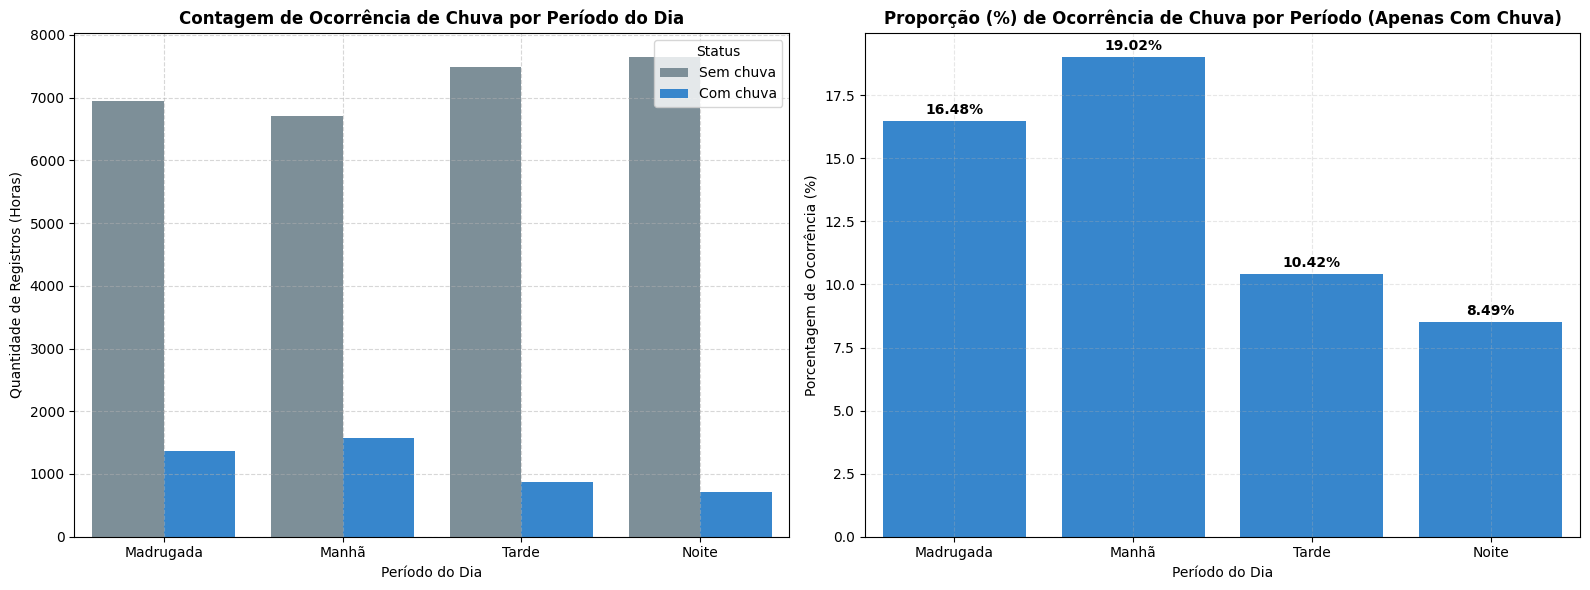

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Garantir conversão para datetime
df['datetime'] = pd.to_datetime(df['datetime'])

# Como o dataset original geralmente já está em UTC ou no horário local de Recife (UTC-3),
# se a coluna contiver informação de timezone, convertemos para Recife (America/Recife).
# Caso contrário, assumimos que já está localizado no horário de Recife ou fazemos a extração direta.
if df['datetime'].dt.tz is None:
    # Caso não tenha fuso, assume-se local UTC-3 de Recife diretamente
    horas = df['datetime'].dt.hour
else:
    # Caso tenha fuso, converte explicitamente para o fuso de Recife
    horas = df['datetime'].dt.tz_convert('America/Recife').dt.hour

# Definir função para categorizar o período do dia
def categorizar_periodo(hora):
    if 0 <= hora < 6:
        return 'Madrugada'
    elif 6 <= hora < 12:
        return 'Manhã'
    elif 12 <= hora < 18:
        return 'Tarde'
    else:
        return 'Noite'

# Criar a coluna de período do dia
df['periodo_dia'] = horas.apply(categorizar_periodo)

# Definir a classe de chuva (se já não existir)
df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'] = pd.to_numeric(df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'], errors='coerce')
df['classe_chuva'] = df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'].apply(
    lambda x: 'Com chuva' if x > 0 else ('Sem chuva' if x == 0 else None)
)

# Filtrar nulos para a análise comparativa
df_analise = df.dropna(subset=['periodo_dia', 'classe_chuva']).copy()

# Definir ordem desejada para os períodos
ordem_periodos = ['Madrugada', 'Manhã', 'Tarde', 'Noite']
df_analise['periodo_dia'] = pd.Categorical(df_analise['periodo_dia'], categories=ordem_periodos, ordered=True)

# 2. Comparar a ocorrência de chuva por período
tabela_frequencia = pd.crosstab(df_analise['periodo_dia'], df_analise['classe_chuva'])
tabela_proporcao = pd.crosstab(df_analise['periodo_dia'], df_analise['classe_chuva'], normalize='index') * 100

# Garantir que as colunas estejam na ordem exata de exibição desejada para alinhar as cores
ordem_classes = ['Sem chuva', 'Com chuva']
tabela_frequencia = tabela_frequencia[ordem_classes]

print("--- Quantidade de Eventos por Período do Dia ---")
display(tabela_frequencia)

print("\n--- Proporção (%) dentro de cada Período do Dia ---")
display(tabela_proporcao[ordem_classes].round(2))

# Definir cores personalizadas para classe_chuva
paleta_personalizada = {
    'Sem chuva': '#78909C',
    'Com chuva': '#1E88E5'
}

# 3. Visualização
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Gráfico 1: Quantidade total de registros por classe de chuva e período
sns.countplot(
    data=df_analise,
    x='periodo_dia',
    hue='classe_chuva',
    hue_order=ordem_classes,
    palette=paleta_personalizada,
    ax=axes[0]
)
axes[0].set_title('Contagem de Ocorrência de Chuva por Período do Dia', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Período do Dia')
axes[0].set_ylabel('Quantidade de Registros (Horas)')
axes[0].legend(title='Status')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Gráfico 2: Percentual apenas de ocorrência de 'Com chuva' por período para maior resolução
sns.barplot(
    x=tabela_proporcao.index,
    y=tabela_proporcao['Com chuva'],
    color=paleta_personalizada['Com chuva'],
    ax=axes[1]
)
axes[1].set_title('Proporção (%) de Ocorrência de Chuva por Período (Apenas Com Chuva)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Período do Dia')
axes[1].set_ylabel('Porcentagem de Ocorrência (%)')

# Definir os ticks corretamente para evitar avisos do Matplotlib
axes[1].set_xticks(range(len(ordem_periodos)))
axes[1].set_xticklabels(ordem_periodos)
axes[1].grid(True, linestyle='--', alpha=0.3)

# Adicionar rótulos de valores em cima das barras para facilitar a leitura detalhada
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.2f}%",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=10,
                    fontweight='bold')

plt.tight_layout()
plt.show()

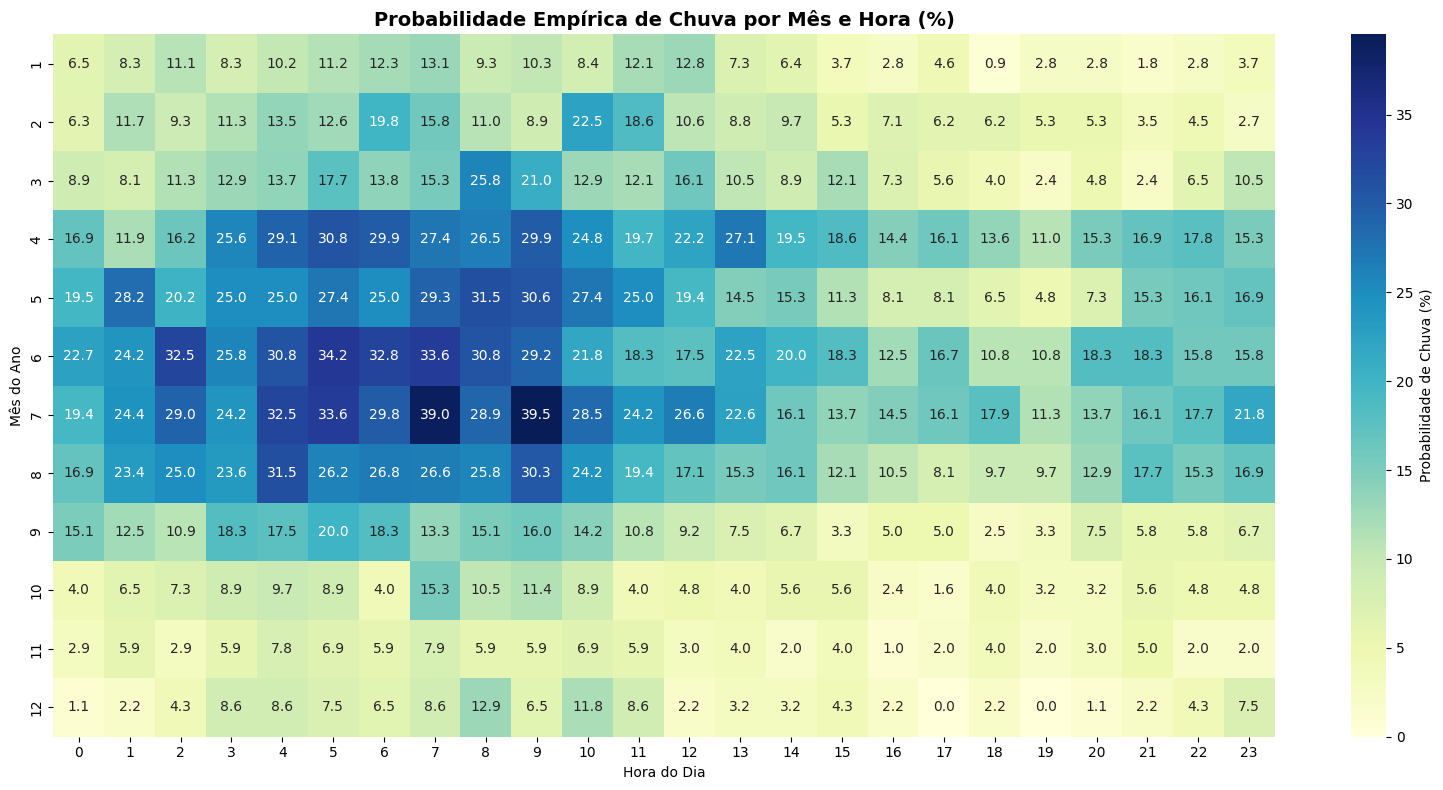

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Garantir que a coluna datetime está no formato correto
df['datetime'] = pd.to_datetime(df['datetime'])

# 2. Extrair mês e hora
df['mes'] = df['datetime'].dt.month
df['hora'] = df['datetime'].dt.hour

# 3. Criar a variável indicadora se choveu (1 se precipitação > 0, 0 se igual a 0)
df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'] = pd.to_numeric(df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'], errors='coerce')
df['choveu'] = df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'].apply(lambda x: 1 if x > 0 else (0 if x == 0 else None))

# Filtrar nulos na indicação de chuva
df_pivot = df.dropna(subset=['choveu', 'mes', 'hora']).copy()

# 4. Criar a pivot table com a probabilidade empírica (média de 'choveu')
pivot_chuva = df_pivot.pivot_table(
    index='mes',
    columns='hora',
    values='choveu',
    aggfunc='mean'
) * 100  # Converter para porcentagem

# 5. Visualizar com um heatmap do Seaborn
plt.figure(figsize=(16, 8))
sns.heatmap(
    pivot_chuva,
    annot=True,
    fmt=".1f",
    cmap='YlGnBu',
    cbar_kws={'label': 'Probabilidade de Chuva (%)'}
)

plt.title('Probabilidade Empírica de Chuva por Mês e Hora (%)', fontsize=14, fontweight='bold')
plt.xlabel('Hora do Dia')
plt.ylabel('Mês do Ano')
plt.tight_layout()
plt.show()

--- Limiares de Chuva Extrema (calculados sobre horas com chuva > 0 mm) ---
Total de horas com chuva: 4526
P95: 6.40 mm/h
P99: 15.20 mm/h

--- Quantidade de Horas por Classe de Evento ---


,quantidade_horas,proporcao_%
classe_evento,,
Normal,33094,99.35
Extremo (> P95),173,0.52
Extremo (> P99),45,0.14


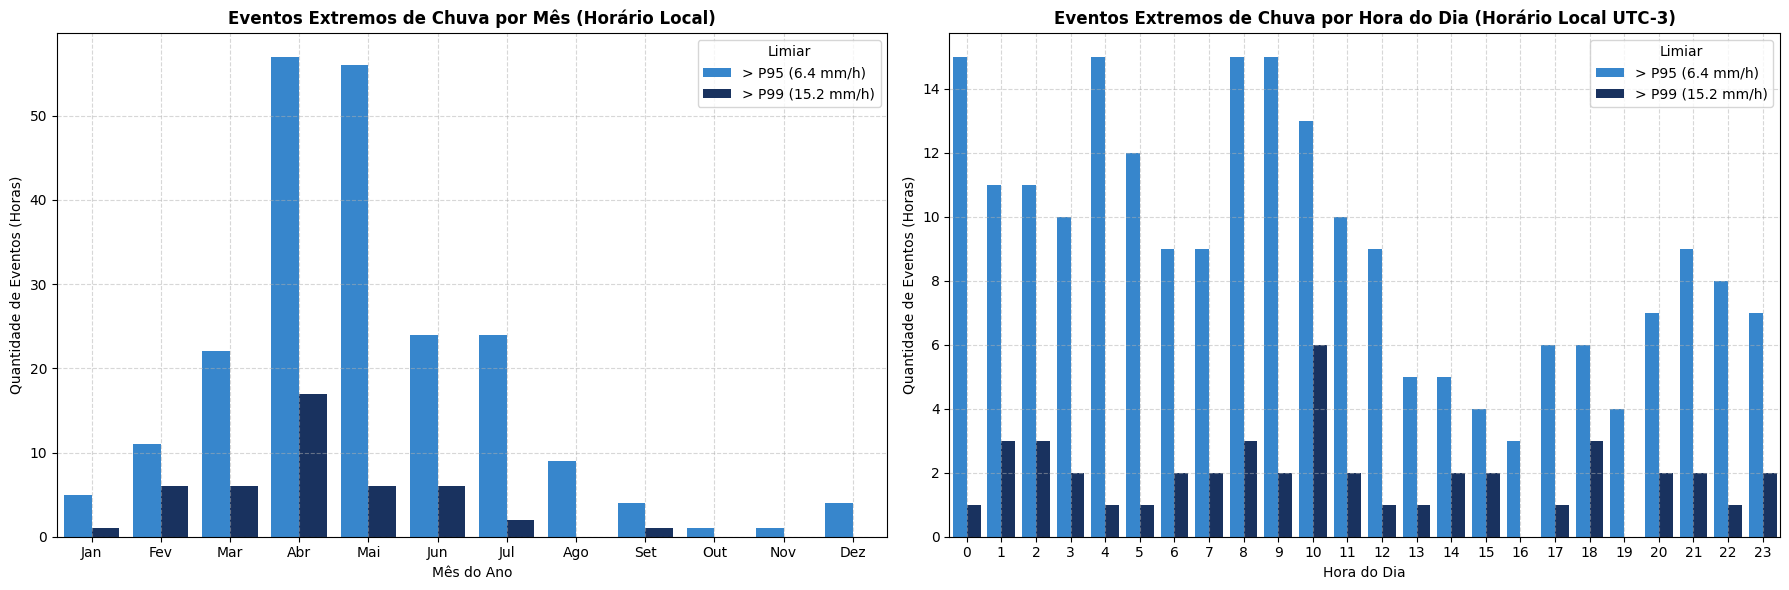

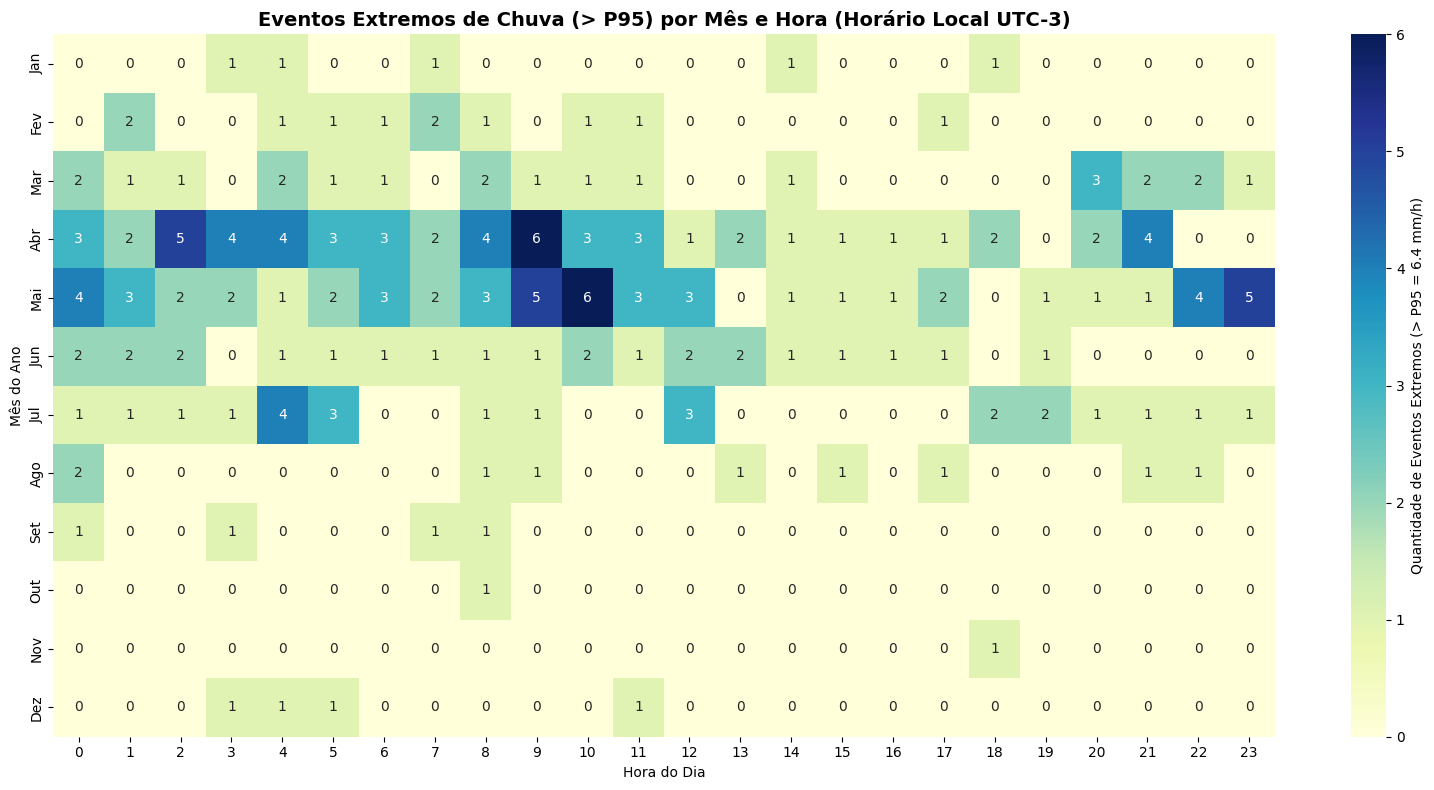

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Garantir estrutura básica dos dados e converter para o horário local (UTC-3)
df['datetime'] = pd.to_datetime(df['datetime'])

# Verificar se o datetime é naive (sem fuso). Se sim, localiza como UTC e converte para America/Recife
if df['datetime'].dt.tz is None:
    df['datetime_local'] = df['datetime'].dt.tz_localize('UTC').dt.tz_convert('America/Recife')
else:
    df['datetime_local'] = df['datetime'].dt.tz_convert('America/Recife')

df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'] = pd.to_numeric(df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'], errors='coerce')
df['mes'] = df['datetime_local'].dt.month
df['hora'] = df['datetime_local'].dt.hour

# 2. Calcular os percentis P95 e P99 considerando apenas as horas com chuva (> 0 mm)
coluna_chuva = 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'
chuva_positiva = df.loc[df[coluna_chuva] > 0, coluna_chuva]

p95 = chuva_positiva.quantile(0.95)
p99 = chuva_positiva.quantile(0.99)

print("--- Limiares de Chuva Extrema (calculados sobre horas com chuva > 0 mm) ---")
print(f"Total de horas com chuva: {len(chuva_positiva)}")
print(f"P95: {p95:.2f} mm/h")
print(f"P99: {p99:.2f} mm/h")

# 3. Classificar os eventos
df['extremo_p95'] = df[coluna_chuva] > p95
df['extremo_p99'] = df[coluna_chuva] > p99

def classificar_evento(valor):
    if pd.isna(valor):
        return None
    elif valor > p99:
        return 'Extremo (> P99)'
    elif valor > p95:
        return 'Extremo (> P95)'
    else:
        return 'Normal'

df['classe_evento'] = df[coluna_chuva].apply(classificar_evento)

resumo_eventos = (
    df['classe_evento']
    .value_counts()
    .reindex(['Normal', 'Extremo (> P95)', 'Extremo (> P99)'])
    .to_frame('quantidade_horas')
)
resumo_eventos['proporcao_%'] = (resumo_eventos['quantidade_horas'] / resumo_eventos['quantidade_horas'].sum() * 100).round(2)

print("\n--- Quantidade de Horas por Classe de Evento ---")
display(resumo_eventos)

# 4. Preparar as tabelas de contagem por mês e por hora
nomes_meses = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
meses = range(1, 13)
horas = range(0, 24)

# Formato longo para os gráficos de barras agrupadas (P95 e P99)
df_extremos = pd.concat([
    df.loc[df['extremo_p95'], ['mes', 'hora']].assign(limiar=f'> P95 ({p95:.1f} mm/h)'),
    df.loc[df['extremo_p99'], ['mes', 'hora']].assign(limiar=f'> P99 ({p99:.1f} mm/h)')
], ignore_index=True)

ordem_limiares = [f'> P95 ({p95:.1f} mm/h)', f'> P99 ({p99:.1f} mm/h)']
paleta_extremos = {
    ordem_limiares[0]: '#1E88E5',
    ordem_limiares[1]: '#0D2F6B'
}

# Matriz mês × hora com a contagem de eventos acima do P95
pivot_extremos = (
    df[df['extremo_p95']]
    .pivot_table(index='mes', columns='hora', values=coluna_chuva, aggfunc='count')
    .reindex(index=meses, columns=horas)
    .fillna(0)
    .astype(int)
)
pivot_extremos.index = nomes_meses

# 5. Visualização: eventos extremos por mês e por hora
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

# Gráfico 5.1: Eventos extremos por mês
sns.countplot(
    data=df_extremos,
    x='mes',
    hue='limiar',
    hue_order=ordem_limiares,
    order=list(meses),
    palette=paleta_extremos,
    ax=axes[0]
)
axes[0].set_title('Eventos Extremos de Chuva por Mês (Horário Local)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Mês do Ano')
axes[0].set_ylabel('Quantidade de Eventos (Horas)')
axes[0].set_xticks(range(12))
axes[0].set_xticklabels(nomes_meses)
axes[0].legend(title='Limiar')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Gráfico 5.2: Eventos extremos por hora
sns.countplot(
    data=df_extremos,
    x='hora',
    hue='limiar',
    hue_order=ordem_limiares,
    order=list(horas),
    palette=paleta_extremos,
    ax=axes[1]
)
axes[1].set_title('Eventos Extremos de Chuva por Hora do Dia (Horário Local UTC-3)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hora do Dia')
axes[1].set_ylabel('Quantidade de Eventos (Horas)')
axes[1].legend(title='Limiar')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Gráfico 5.3: Heatmap de mês × hora (eventos acima do P95)
plt.figure(figsize=(16, 8))
sns.heatmap(
    pivot_extremos,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    cbar_kws={'label': f'Quantidade de Eventos Extremos (> P95 = {p95:.1f} mm/h)'}
)

plt.title('Eventos Extremos de Chuva (> P95) por Mês e Hora (Horário Local UTC-3)', fontsize=14, fontweight='bold')
plt.xlabel('Hora do Dia')
plt.ylabel('Mês do Ano')
plt.tight_layout()
plt.show()

--- Estatísticas dos Episódios de Chuva Consecutiva ---


,quantidade,duracao_media_horas,volume_medio_mm,pico_maximo_mm_h
tipo_episodio,,,,
Curto (2-4h),694,2.50,4.19,31.6
Isolado (1h),1321,1.00,0.81,22.6
Longa Duração (5h+),173,8.51,20.41,45.6



--- Top 10 Episódios Mais Intensos (Por Volume Acumulado) ---


,inicio_datetime,fim_datetime,duracao_horas,volume_acumulado,pico_intensidade,tipo_episodio
0,2021-05-13 08:00:00,2021-05-14 15:00:00,32,192.0,18.8,Longa Duração (5h+)
1,2019-06-12 20:00:00,2019-06-13 20:00:00,25,147.0,19.8,Longa Duração (5h+)
2,2021-04-10 15:00:00,2021-04-11 08:00:00,18,135.4,23.2,Longa Duração (5h+)
3,2021-04-11 17:00:00,2021-04-12 03:00:00,11,87.8,45.6,Longa Duração (5h+)
4,2019-07-23 22:00:00,2019-07-24 17:00:00,20,87.4,15.0,Longa Duração (5h+)
5,2020-03-15 23:00:00,2020-03-16 04:00:00,6,76.0,41.8,Longa Duração (5h+)
6,2020-06-14 00:00:00,2020-06-14 19:00:00,20,66.2,5.4,Longa Duração (5h+)
7,2018-04-30 02:00:00,2018-04-30 16:00:00,15,65.0,21.6,Longa Duração (5h+)
8,2021-05-04 01:00:00,2021-05-04 11:00:00,11,59.4,14.4,Longa Duração (5h+)
9,2020-07-17 17:00:00,2020-07-18 04:00:00,12,58.8,18.4,Longa Duração (5h+)


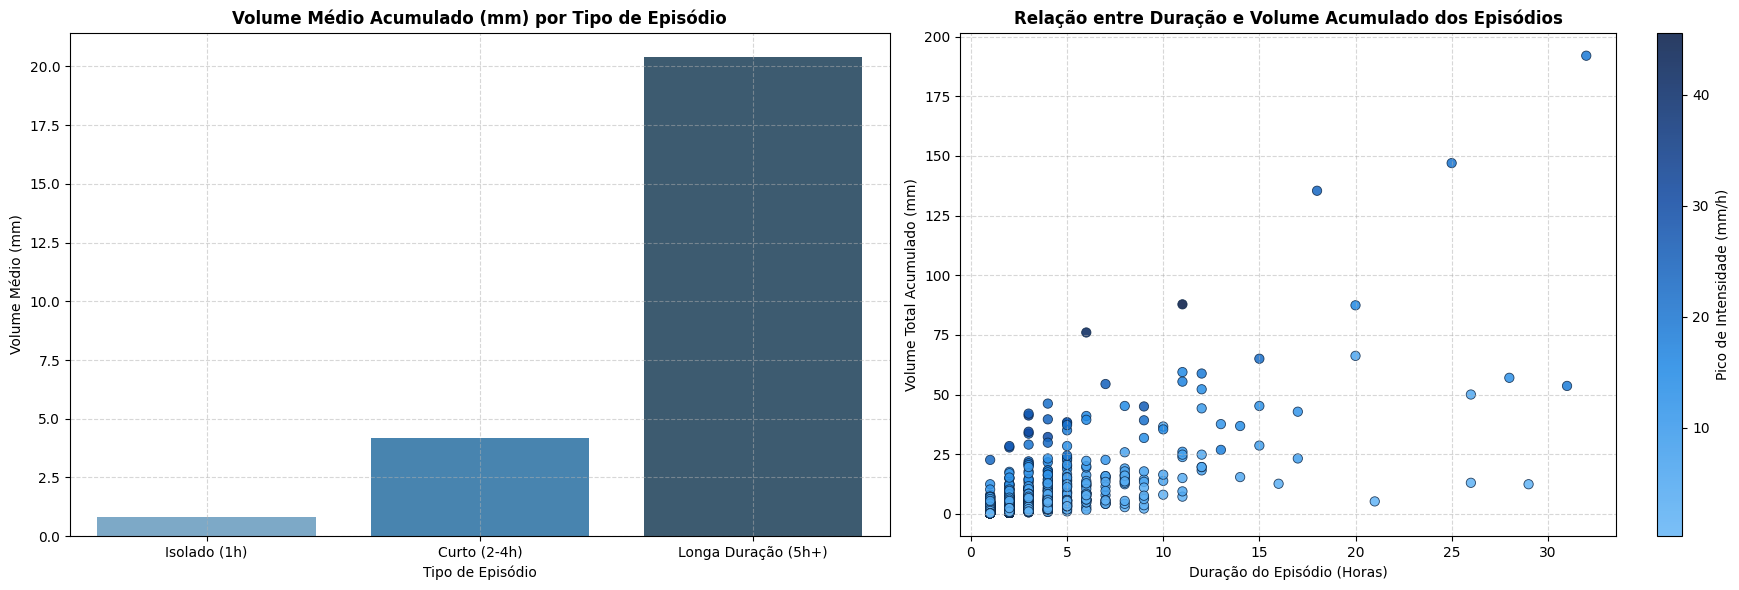

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# 1. Garantir que os dados básicos estejam estruturados e ordenados temporalmente
df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'] = pd.to_numeric(df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'], errors='coerce')
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values('datetime').reset_index(drop=True)

# Criar indicadora de chuva ativa
df['choveu_bool'] = df['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)'] > 0

# 2. Identificar episódios consecutivos de chuva
# Um novo episódio começa sempre que mudamos de 'sem chuva' para 'com chuva'
# Usamos a soma acumulada da negação para criar IDs exclusivos para cada bloco de chuva consecutiva
df['episode_id'] = (df['choveu_bool'] != df['choveu_bool'].shift()).cumsum()

# Filtrar apenas as horas em que realmente choveu para agregar os episódios
df_episodios_ativos = df[df['choveu_bool']].copy()

# Agrupar por episode_id para caracterizar cada episódio de chuva consecutiva
episodios = df_episodios_ativos.groupby('episode_id').agg(
    inicio_datetime=('datetime', 'min'),
    fim_datetime=('datetime', 'max'),
    duracao_horas=('PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'count'),
    volume_acumulado=('PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'sum'),
    pico_intensidade=('PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'max')
).reset_index(drop=True)

# Categorizar os episódios com base na duração
def categorizar_episodio(duracao):
    if duracao == 1:
        return 'Isolado (1h)'
    elif 2 <= duracao <= 4:
        return 'Curto (2-4h)'
    else:
        return 'Longa Duração (5h+)'

episodios['tipo_episodio'] = episodios['duracao_horas'].apply(categorizar_episodio)

print("--- Estatísticas dos Episódios de Chuva Consecutiva ---")
summary_ep = episodios.groupby('tipo_episodio').agg(
    quantidade=('duracao_horas', 'count'),
    duracao_media_horas=('duracao_horas', 'mean'),
    volume_medio_mm=('volume_acumulado', 'mean'),
    pico_maximo_mm_h=('pico_intensidade', 'max')
).round(2)
display(summary_ep)

print("\n--- Top 10 Episódios Mais Intensos (Por Volume Acumulado) ---")
display(episodios.sort_values(by='volume_acumulado', ascending=False).head(10).reset_index(drop=True))

# 3. Visualização dos Episódios
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

ordem_tipos = ['Isolado (1h)', 'Curto (2-4h)', 'Longa Duração (5h+)']

# Gráfico 1: Distribuição do tipo de episódio pelo volume acumulado médio
sns.barplot(
    data=episodios,
    x='tipo_episodio',
    y='volume_acumulado',
    estimator=np.mean,
    errorbar=None,
    hue='tipo_episodio',
    palette=dict(zip(ordem_tipos, sns.color_palette('Blues_d', n_colors=3))),
    legend=False,
    order=ordem_tipos,
    ax=axes[0]
)
axes[0].set_title('Volume Médio Acumulado (mm) por Tipo de Episódio', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tipo de Episódio')
axes[0].set_ylabel('Volume Médio (mm)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Gráfico 2: Dispersão Duração vs Volume Acumulado (com destaque para pico de intensidade)
# Colormap azul que começa em um azul médio (não quase branco), garantindo contraste com o fundo branco
cmap_azul = LinearSegmentedColormap.from_list(
    'azul_contraste',
    ['#64B5F6', '#1E88E5', '#0D47A1', '#041A47']
)

scatter = axes[1].scatter(
    data=episodios,
    x='duracao_horas',
    y='volume_acumulado',
    c='pico_intensidade',
    cmap=cmap_azul,
    alpha=0.85,
    edgecolors='#0B2545',
    linewidths=0.6,
    s=45
)
fig.colorbar(scatter, ax=axes[1], label='Pico de Intensidade (mm/h)')
axes[1].set_title('Relação entre Duração e Volume Acumulado dos Episódios', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Duração do Episódio (Horas)')
axes[1].set_ylabel('Volume Total Acumulado (mm)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## **Objetivo principal da EDA**

- Identificar padrões que antecedem a ocorrência de chuva;
- Compreender a distribuição da precipitação;
- Identificar as variáveis meteorológicas associadas à ocorrência de chuva.

## **Análises realizadas**

- Análise das **médias e medianas** de todas as variáveis meteorológicas;
- Análise da **matriz de correlação**, utilizando Pearson e Spearman, sem diferenças relevantes nos resultados;
- Análise da relação entre algumas variáveis meteorológicas e a precipitação;
- **Análises estratificadas**, considerando:
  - Dias sem chuva vs. dias com chuva;
  - Intensidade da chuva;
  - Precipitação por período do dia;
  - Meses secos vs. meses chuvosos;
- Investigação de **eventos extremos de precipitação**, utilizando os percentis P95 e P99.